# Dispersion in fibres: material, waveguide and intermodal, and the zero-dispersion wavelength

A pulse in a fibre spreads because its parts travel at different speeds.
Notebook 115 (light in a fibre) found the largest effect with rays: different modes take
different times (**intermodal dispersion**). In a single-mode fibre that
is gone, and what remains is **chromatic dispersion**: the different
wavelengths in the pulse travel at different group velocities, because
the glass is dispersive (material dispersion) and because the mode itself
changes with the wavelength (waveguide dispersion). A third, small effect
is **polarization mode dispersion** from random birefringence.

This notebook computes all of them from the index profile and Fleming's
Sellmeier data of GeO₂-doped silica:

1. the group delay of a mode and the dispersion parameter D,
2. material dispersion of silica and doped silica,
3. the standard single-mode fibre: D(λ), the zero-dispersion wavelength
   and Gloge's waveguide dispersion,
4. profiles that move the zero: dispersion-shifted and dispersion-flattened
   fibres,
5. intermodal dispersion from the modes of multimode fibres, against the
   rays of notebook 115 (light in a fibre), and the profile dispersion that makes the best
   graded fibre depend on the wavelength,
6. polarization mode dispersion.

Units: wavelengths in µm (nm in the plots), D in ps/(nm km), delays in
ps/km. Notebook 118 (pulse broadening) turns these numbers into pulse shapes and bit rates.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import fibres, modes, ultrafast, sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(117)

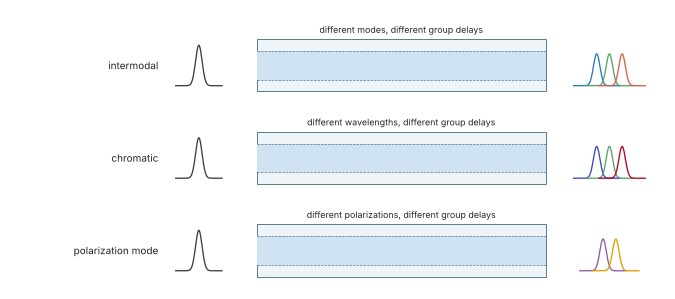

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.6))
sketch.dispersion_mechanisms(ax)
plt.show()

## 1. Group delay and the dispersion parameter

A mode with the propagation constant $\beta(\omega) = kn_{eff}$ carries a
pulse at the group velocity $v_g = d\omega/d\beta$. Through a length $L$ the
**group delay** is

$$
\tau = L\frac{d\beta}{d\omega} = \frac{L}{c}N_g, \qquad N_g = n_{eff} - \lambda\frac{dn_{eff}}{d\lambda},
$$

with the group index $N_g$. If $\tau$ depends on the wavelength, a source of
spectral width $\Delta\lambda$ spreads by $\Delta\tau = |D|L\Delta\lambda$, with the
**dispersion parameter**

$$
D = \frac{1}{L}\frac{d\tau}{d\lambda} = -\frac{\lambda}{c}\frac{d^2n_{eff}}{d\lambda^2}
= -\frac{2\pi c}{\lambda^2}\beta_2 \quad [\mathrm{ps/(nm\,km)}].
$$

$D > 0$ (anomalous dispersion, $\beta_2 < 0$): longer wavelengths are slower.
`fibres.group_index()` and `fibres.dispersion()` differentiate the
effective index from the mode solver numerically (five-point stencils),
with the dispersion of the core and cladding glasses and of $\Delta$
included. The fibre is the step-index model of a standard single-mode
fibre, `fibres.smf28()` (notebook 116, fibre modes).

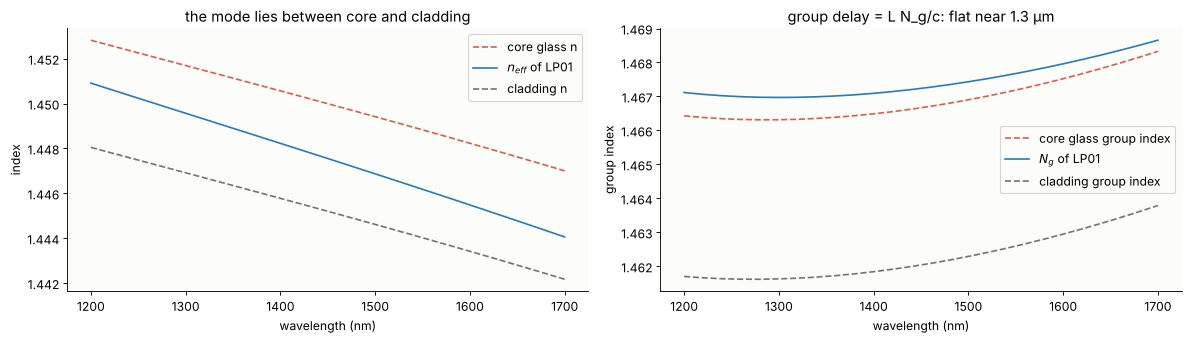

group delay at 1550 nm: 4.9 µs per km; minimum group index 1.46697 at 1300 nm


In [3]:
smf = fibres.smf28()
wl = np.linspace(1.20, 1.70, 26)
kw = dict(r_max=30, n_points=3000)
n_eff = fibres.effective_index(smf, wl, **kw)
N_g = fibres.group_index(smf, wl, **kw)
n_core, n_clad = smf.n_core(wl), smf.n_clad(wl)
_, Ng_core = fibres.material_dispersion(smf.n_core, wl)
_, Ng_clad = fibres.material_dispersion(smf.n_clad, wl)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].plot(wl*1E3, n_core, color=RED, ls="--", label="core glass n")
axes[0].plot(wl*1E3, n_eff, color=BLUE, label=r"$n_{eff}$ of LP01")
axes[0].plot(wl*1E3, n_clad, color=GREY, ls="--", label="cladding n")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel("index"); axes[0].legend()
axes[0].set_title("the mode lies between core and cladding")
axes[1].plot(wl*1E3, Ng_core, color=RED, ls="--", label="core glass group index")
axes[1].plot(wl*1E3, N_g, color=BLUE, label=r"$N_g$ of LP01")
axes[1].plot(wl*1E3, Ng_clad, color=GREY, ls="--", label="cladding group index")
axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("group index"); axes[1].legend()
axes[1].set_title("group delay = L N_g/c: flat near 1.3 µm")
plt.tight_layout()
plt.show()
i = np.argmin(N_g)
print("group delay at 1550 nm: {:.1f} µs per km; minimum group index {:.5f} at {:.0f} nm".format(
      np.interp(1.55, wl, N_g)/fibres.C_UM_PER_PS*1E3, N_g[i], wl[i]*1E3))

The group index has a minimum near 1.3 µm: there the group delay does not
change with the wavelength to first order, $D = 0$. The group delay of a
kilometre is 4.9 µs, and what matters for pulses is how much it changes
across the spectrum of the pulse: a few ps per nm and km.

## 2. Material dispersion

Silica absorbs in the ultraviolet (electronic transitions) and in the
infrared (Si–O vibrations), and its index between the two falls with the
wavelength with an inflection point near 1.27 µm: there the material
dispersion vanishes. GeO₂ raises the index and moves the absorption edges
outwards, shifting the zero a little to longer wavelengths.
`fibres.material_dispersion()` gives D and the group index of any glass,
here from `materials.germania_silica_index()`. As a check, $\beta_2$ from D
equals the GVD of `ultrafast.gvd()` (notebook 81, ultrashort pulses): 1 fs²/mm is 1 ps²/km.

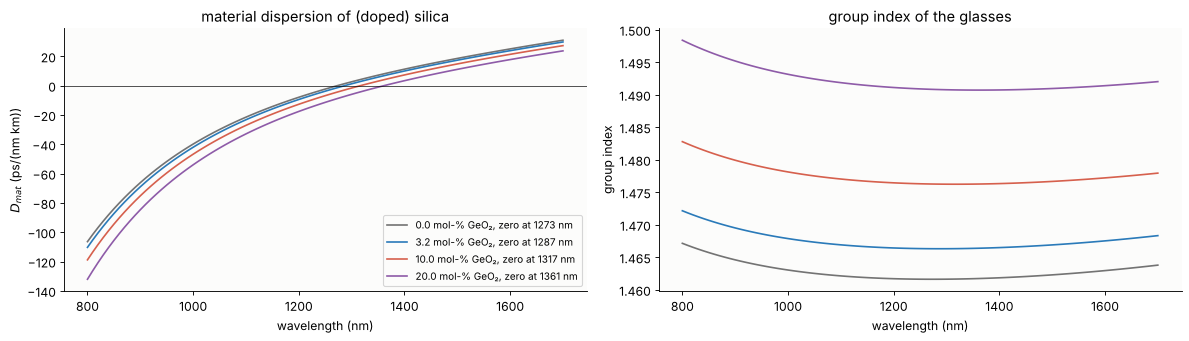

silica at 1550 nm: D = 21.91 ps/(nm km) -> beta2 = -27.947 ps²/km; ultrafast.gvd(): -27.947 fs²/mm
silica at 850 nm: D = -84.0 ps/(nm km)


In [4]:
wl_m = np.linspace(0.8, 1.7, 91)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for x, c in ((0.0, GREY), (0.032, BLUE), (0.10, RED), (0.20, PURPLE)):
    n = fibres.ge_doped(x)[0]
    D, Ng = fibres.material_dispersion(n, wl_m)
    l0 = brentq(lambda w: fibres.material_dispersion(n, w)[0], 1.1, 1.5)
    axes[0].plot(wl_m*1E3, D, color=c, label=f"{100*x:.1f} mol-% GeO₂, zero at {l0*1E3:.0f} nm")
    axes[1].plot(wl_m*1E3, Ng, color=c)
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel(r"$D_{mat}$ (ps/(nm km))"); axes[0].legend(fontsize=9)
axes[0].set_title("material dispersion of (doped) silica")
axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("group index")
axes[1].set_title("group index of the glasses")
plt.tight_layout()
plt.show()

n_si_nm = lambda w_nm: fibres.ge_doped(0.0)[0](w_nm*1E-3)
D_si = fibres.material_dispersion(fibres.ge_doped(0.0)[0], 1.55)[0]
print("silica at 1550 nm: D = {:.2f} ps/(nm km) -> beta2 = {:.3f} ps²/km; ultrafast.gvd(): {:.3f} fs²/mm".format(
      D_si, fibres.beta2_from_D(D_si, 1550), ultrafast.gvd(n_si_nm, 1550.0)))
print("silica at 850 nm: D = {:.1f} ps/(nm km)".format(fibres.material_dispersion(fibres.ge_doped(0.0)[0], 0.85)[0]))

At 850 nm, the first window, the material alone gives −84 ps/(nm km): a
1 nm wide source spreads by 84 ps per kilometre. At 1550 nm D is +22, at
1270 nm it is zero.

## 3. The standard single-mode fibre

The mode of a single-mode fibre is partly in the core and partly in the
cladding, and the share in the cladding grows with the wavelength (the mode
field diameter grows, notebook 116, fibre modes). Even without any material dispersion
the group delay therefore depends on the wavelength: the **waveguide
dispersion**. Gloge's classic split for the weakly guiding step-index fibre
is

$$
D \approx D_{mat} + D_{wg}, \qquad
D_{wg} = -\frac{N_2\Delta}{c\lambda}\,V\frac{d^2(Vb)}{dV^2},
$$

with the group index $N_2$ of the cladding and the normalized propagation
constant $b(V)$ of LP$_{01}$ (`fibres.waveguide_dispersion()`,
`fibres.vb_derivatives()`). $V\,d^2(Vb)/dV^2$ is positive in the
single-mode range, so the waveguide dispersion is negative and pushes the
zero from 1.27 µm to longer wavelengths. The full calculation
(`fibres.dispersion()`) differentiates $n_{eff}$ from the mode solver and
needs no split.

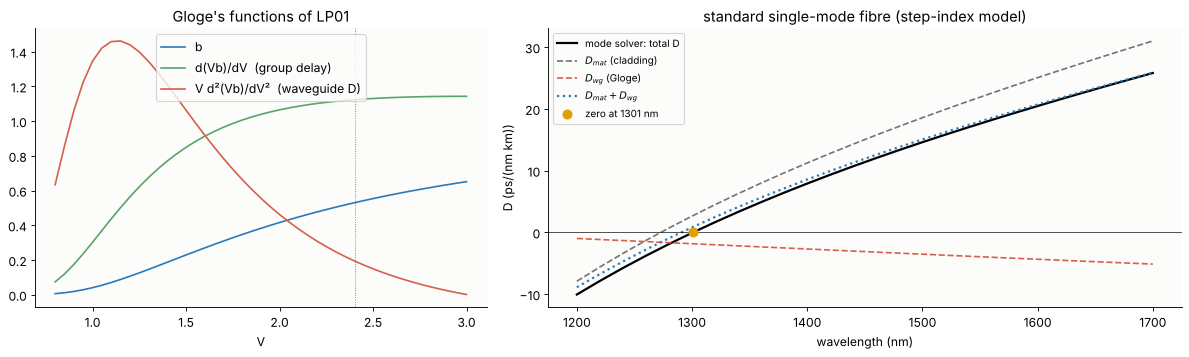

zero-dispersion wavelength 1300.8 nm (G.652: 1300 to 1324), slope S0 = 0.0883 ps/(nm² km) (G.652: <= 0.092)
D at 1550 nm: 17.63 ps/(nm km) (SMF-28: about 17 to 18); Gloge split: 17.97


In [5]:
Vv = np.linspace(0.8, 3.0, 45)
b, dVb, Vd2 = fibres.vb_derivatives(Vv)
wl_d = np.linspace(1.20, 1.70, 26)
D_tot = fibres.dispersion(smf, wl_d, **kw)
D_mat_core = fibres.material_dispersion(smf.n_core, wl_d)[0]
D_mat_clad = fibres.material_dispersion(smf.n_clad, wl_d)[0]
D_wg = fibres.waveguide_dispersion(smf, wl_d)
l0 = brentq(lambda w: fibres.dispersion(smf, w, **kw), 1.25, 1.40)
S0 = fibres.dispersion_slope(smf, l0, **kw)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(Vv, b, color=BLUE, label="b")
axes[0].plot(Vv, dVb, color=GREEN, label="d(Vb)/dV  (group delay)")
axes[0].plot(Vv, Vd2, color=RED, label=r"V d²(Vb)/dV²  (waveguide D)")
axes[0].axvline(2.405, color=GREY, ls=":", lw=0.8)
axes[0].set_xlabel("V"); axes[0].legend(); axes[0].set_title("Gloge's functions of LP01")
axes[1].plot(wl_d*1E3, D_tot, color="k", lw=2, label="mode solver: total D")
axes[1].plot(wl_d*1E3, D_mat_clad, color=GREY, ls="--", label=r"$D_{mat}$ (cladding)")
axes[1].plot(wl_d*1E3, D_wg, color=RED, ls="--", label=r"$D_{wg}$ (Gloge)")
axes[1].plot(wl_d*1E3, D_mat_clad + D_wg, color=BLUE, ls=":", lw=2, label=r"$D_{mat} + D_{wg}$")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].plot(l0*1E3, 0, "o", color=ORANGE, ms=8, label=f"zero at {l0*1E3:.0f} nm")
axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("D (ps/(nm km))"); axes[1].legend(fontsize=9)
axes[1].set_title("standard single-mode fibre (step-index model)")
plt.tight_layout()
plt.show()
print("zero-dispersion wavelength {:.1f} nm (G.652: 1300 to 1324), slope S0 = {:.4f} ps/(nm² km) (G.652: <= 0.092)".format(
      l0*1E3, S0))
print("D at 1550 nm: {:.2f} ps/(nm km) (SMF-28: about 17 to 18); Gloge split: {:.2f}".format(
      fibres.dispersion(smf, 1.55, **kw), np.interp(1.55, wl_d, D_mat_clad + D_wg)))

Gloge's sum with the cladding glass agrees with the full calculation to a
few tenths of a ps/(nm km); the remaining difference is the dispersion of
$\Delta$ itself (profile dispersion) and the part of the mode in the core
glass. The model fibre has the zero at 1301 nm and 17.6 ps/(nm km) at
1550 nm, which is what the data sheet promises.

## 4. Moving the zero: dispersion-shifted and dispersion-flattened fibres

Silica has its lowest loss at 1550 nm (notebook 120, fibre link) but the standard
fibre its zero dispersion at 1300 nm. A stronger waveguide dispersion moves
the zero: a small core with a large index difference (more of the mode
feels the change of the core size with the wavelength). Two classic
designs, found with the same mode solver by a small search over the
parameters:

- **dispersion-shifted** (ITU-T G.653): a triangular core
  (`fibres.triangular()`, radius 3.2 µm, 10 mol-% GeO₂ on the axis), zero
  dispersion at 1550 nm,
- **dispersion-flattened**: a W profile (`fibres.w_profile()`): a step core
  (radius 2.6 µm, 8 mol-%) surrounded by a depressed ring (to 1.6 core radii,
  1.1 times as deep below the cladding as the core lies above it, in a real
  fibre fluorine-doped silica). The ring cuts the outer tail of the mode at
  long wavelengths and bends D(λ) back down: small dispersion over the
  whole range from 1.3 to 1.6 µm.

fibre                           λ0 (nm)        D1310        D1550 MFD1550 (µm)


standard (G.652)                   1301         0.81        17.63        10.48


dispersion-shifted (G.653)         1550       -16.59         0.02         7.52


dispersion-flattened (W)     1352, 1607        -1.78         1.70         5.39


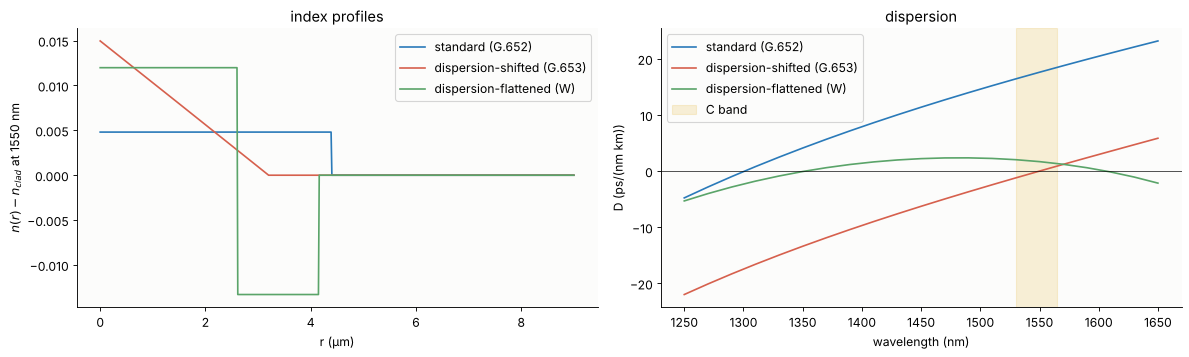

In [6]:
dsf = fibres.triangular(3.2, *fibres.ge_doped(0.10), name="dispersion-shifted")
dff = fibres.w_profile(2.6, 1.6, 1.1, *fibres.ge_doped(0.08), name="dispersion-flattened")
designs = [("standard (G.652)", smf, BLUE), ("dispersion-shifted (G.653)", dsf, RED),
           ("dispersion-flattened (W)", dff, GREEN)]
wl_p = np.linspace(1.25, 1.65, 21)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
r = np.linspace(0, 9, 600)
print("{:28s} {:>10s} {:>12s} {:>12s} {:>12s}".format("fibre", "λ0 (nm)", "D1310", "D1550", "MFD1550 (µm)"))
for name, f, c in designs:
    axes[0].plot(r, f.n(r, 1.55) - f.n_clad(1.55), color=c, label=name)
    D = fibres.dispersion(f, wl_p, r_max=30, n_points=2500)
    axes[1].plot(wl_p*1E3, D, color=c, label=name)
    zeros = [brentq(lambda w: fibres.dispersion(f, w, r_max=30, n_points=2500), wl_p[j], wl_p[j + 1])
             for j in np.nonzero(np.sign(D[:-1]) != np.sign(D[1:]))[0]]
    mfd = fibres.petermann_mfd(fibres.scalar_mode(f, 1.55, r_max=30, n_points=2500))
    print("{:28s} {:>10s} {:12.2f} {:12.2f} {:12.2f}".format(name, ", ".join(f"{z*1E3:.0f}" for z in zeros),
          float(fibres.dispersion(f, 1.31, r_max=30, n_points=2500)), float(D[np.argmin(abs(wl_p - 1.55))]), mfd))
axes[0].set_xlabel("r (µm)"); axes[0].set_ylabel(r"$n(r) - n_{clad}$ at 1550 nm"); axes[0].legend()
axes[0].set_title("index profiles")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].axvspan(1530, 1565, color=ORANGE, alpha=0.15, label="C band")
axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("D (ps/(nm km))"); axes[1].legend()
axes[1].set_title("dispersion")
plt.tight_layout()
plt.show()

The dispersion-shifted fibre has its zero in the C band, with a smaller
mode (higher splice and bend sensitivity, stronger nonlinearity). It was
the fibre of the late 1980s for single-channel links at 1550 nm, and it
turned out to be a poor choice once many wavelengths share a fibre (WDM):
with $D = 0$ the channels stay in phase over long distances and mix by
four-wave mixing. Today's long-haul fibres are **non-zero
dispersion-shifted** (G.655, D of 2 to 10 ps/(nm km) in the C band), and
the standard fibre is used with dispersion compensation (notebook 119, fibre Bragg gratings) or
with digital signal processing in coherent receivers. The flattened
fibre's small D everywhere comes at a price: the depressed ring makes LP01
leaky at long wavelengths, so such fibres are sensitive to bends.

## 5. Intermodal dispersion from the modes

The mode solver gives the group delay of every mode of a multimode fibre
directly, $\tau_{lm} = (L/c)N_{g,lm}$. Below, a 50 µm core with $\Delta = 1\,\%$
at 850 nm, with constant indices (no material dispersion) to compare with
the rays of notebook 115 (light in a fibre) and with the WKB formula
(`fibres.wkb_group_delay()`), for the step, the parabola and the
optimal $\alpha$.

step      : 192 LP modes, the 134 below 70 % depth deviate from WKB by at most 2840.0 ps/km


α = 2     : 100 LP modes, the  49 below 70 % depth deviate from WKB by at most    1.5 ps/km


α = 1.976 : 100 LP modes, the  49 below 70 % depth deviate from WKB by at most    1.6 ps/km


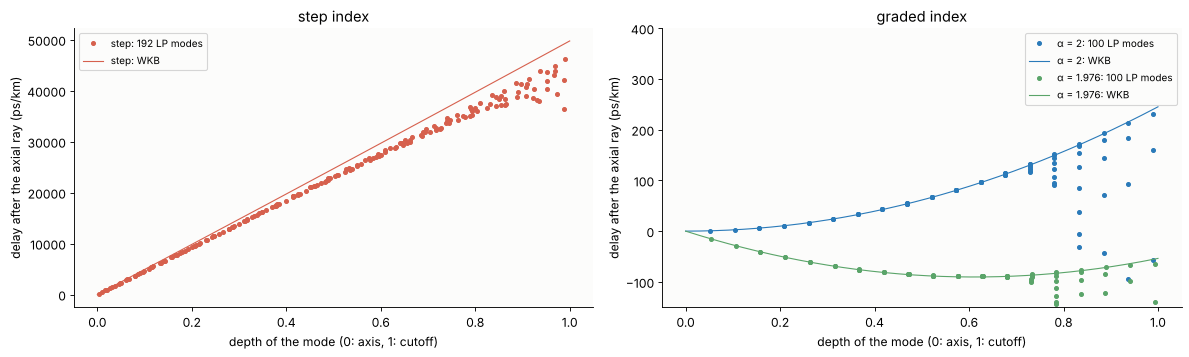

In [7]:
a, n1, Delta, wl0 = 25.0, 1.47, 0.01, 0.85
n2 = n1*np.sqrt(1 - 2*Delta)
k = 2*np.pi/wl0
h = 0.002
kwm = dict(r_max=2.5*a, n_points=2500)


def mode_delays(f):
    """Group delays (ps/km) of all modes, and their depth in the profile."""
    m0 = f.modes(wl0, **kwm)
    mp = {(m.l, m.m): m.n_eff for m in f.modes(wl0 + h, **kwm)}
    mm = {(m.l, m.m): m.n_eff for m in f.modes(wl0 - h, **kwm)}
    out = []
    for m in m0:
        if (m.l, m.m) in mp and (m.l, m.m) in mm:
            Ng = m.n_eff - wl0*(mp[(m.l, m.m)] - mm[(m.l, m.m)])/(2*h)
            depth = (n1**2 - m.n_eff**2)/(2*Delta*n1**2)
            out.append((depth, Ng*1E9/fibres.C_UM_PER_PS, 2 if m.l == 0 else 4))
    return np.array(out)


a_opt = fibres.optimal_alpha(Delta)
t_axis = n1*1E9/fibres.C_UM_PER_PS
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
dd = np.linspace(0, 1, 200)
for name, f, al, c, ax in (("step", fibres.step_index(a, n1, n2), 1E6, RED, axes[0]),
                           ("α = 2", fibres.graded_index(a, 2.0, n1, n2), 2.0, BLUE, axes[1]),
                           (f"α = {a_opt:.3f}", fibres.graded_index(a, a_opt, n1, n2), a_opt, GREEN, axes[1])):
    res = mode_delays(f)
    ax.plot(res[:, 0], res[:, 1] - t_axis, "o", ms=3.5, color=c, label=name + f": {len(res)} LP modes")
    ax.plot(dd, fibres.wkb_group_delay(dd, al, Delta, n1) - t_axis, color=c, lw=1, label=name + ": WKB")
    keep = res[:, 0] < 0.7
    print("{:10s}: {:3d} LP modes, the {:3d} below 70 % depth deviate from WKB by at most {:6.1f} ps/km".format(
          name, len(res), keep.sum(), np.max(np.abs(res[keep, 1] - fibres.wkb_group_delay(res[keep, 0], al, Delta, n1)))))
for ax in axes:
    ax.set_xlabel("depth of the mode (0: axis, 1: cutoff)"); ax.set_ylabel("delay after the axial ray (ps/km)")
    ax.legend(fontsize=9)
axes[1].set_ylim(-150, 400)
axes[0].set_title("step index"); axes[1].set_title("graded index")
plt.tight_layout()
plt.show()

The modes follow the WKB curve, which notebook 115 (light in a fibre) found for the rays:
three pictures of the same physics. The exceptions are the modes close to
cutoff: their fields reach the core boundary and the cladding, where the
profile stops following the power law, and their delays fall off (step
index) or scatter within their mode group (graded index: the low-$l$ members
of a group reach farther out than the ring-shaped high-$l$ ones). In a real
fibre these modes are strongly attenuated by bends and leak into the
cladding, so measurements of the modal bandwidth hardly see them.

### Profile dispersion: the best α depends on the wavelength

With real glasses $\Delta$ itself depends on the wavelength, because GeO₂-doped
and pure silica have slightly different dispersion. Olshansky and Keck's
optimum then reads $\alpha_{opt} = 2 + \epsilon - \Delta(4 + \epsilon)(3 + \epsilon)/(5 + 2\epsilon)$
with the **profile dispersion parameter**
$\epsilon = -\frac{2n_1}{N_1}\frac{\lambda}{\Delta}\frac{d\Delta}{d\lambda}$.
A fibre can be optimal at only one wavelength: the laser-optimized OM3 and
OM4 fibres are made for 850 nm, and their bandwidth at 1300 nm is lower.

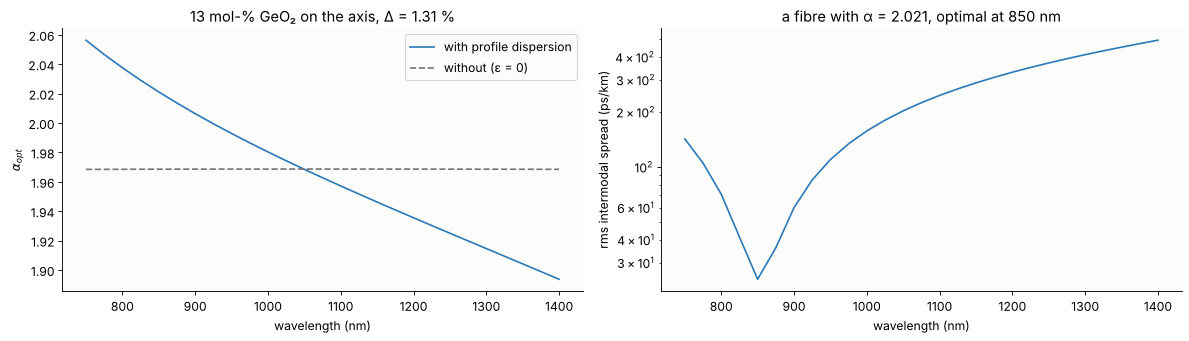

ε at 850 nm: 0.053, at 1300 nm: -0.054
rms spread at 850 nm 24.3 ps/km, at 1300 nm 411.6 ps/km


In [8]:
x_core = 0.13
gi_real = fibres.graded_index(a, 2.0, *fibres.ge_doped(x_core))
wl_e = np.linspace(0.75, 1.40, 27)
step = 0.005
Dl = gi_real.delta(wl_e)
dD = (gi_real.delta(wl_e + step) - gi_real.delta(wl_e - step))/(2*step)
N1 = fibres.material_dispersion(gi_real.n_core, wl_e)[1]
eps = -2*gi_real.n_core(wl_e)/N1*wl_e/Dl*dD
alpha_opt = fibres.optimal_alpha(Dl, eps)
alpha_850 = np.interp(0.85, wl_e, alpha_opt)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
axes[0].plot(wl_e*1E3, alpha_opt, color=BLUE, label="with profile dispersion")
axes[0].plot(wl_e*1E3, fibres.optimal_alpha(Dl), color=GREY, ls="--", label="without (ε = 0)")
axes[0].set_xlabel("wavelength (nm)"); axes[0].set_ylabel(r"$\alpha_{opt}$"); axes[0].legend()
axes[0].set_title(f"{100*x_core:.0f} mol-% GeO₂ on the axis, Δ = {100*gi_real.delta(0.85):.2f} %")
spread = [fibres.wkb_delay_spread(alpha_850, D_, N_, eps=e_) for D_, N_, e_ in zip(Dl, N1, eps)]
axes[1].semilogy(wl_e*1E3, spread, color=BLUE)
axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("rms intermodal spread (ps/km)")
axes[1].set_title(f"a fibre with α = {alpha_850:.3f}, optimal at 850 nm")
plt.tight_layout()
plt.show()
print("ε at 850 nm: {:.3f}, at 1300 nm: {:.3f}".format(np.interp(0.85, wl_e, eps), np.interp(1.3, wl_e, eps)))
print("rms spread at 850 nm {:.1f} ps/km, at 1300 nm {:.1f} ps/km".format(
      np.interp(0.85, wl_e, spread), np.interp(1.3, wl_e, spread)))

The profile dispersion of GeO₂-doped silica is small ($\epsilon$ of about ±0.05)
but it changes the optimal exponent by as much as the optimum is wide: a
profile that is optimal at 850 nm (24 ps/km rms) has 17 times the spread at
1300 nm. Fibres for two windows are a compromise between the two optima.

## 6. Polarization mode dispersion

The two polarizations of LP$_{01}$ are degenerate only in a perfectly round,
unstressed fibre. A real fibre has a small birefringence whose size and
axes change randomly along it (core ellipticity, stress, bends, twist). Its
output is described by two **principal states of polarization** with a
**differential group delay** (DGD) between them. Because the sections add
like a random walk, the mean DGD grows as $\sqrt{L}$, and its value at a given
moment is Maxwell distributed (it drifts with temperature and handling).
`fibres.pmd_dgd()` concatenates randomly oriented birefringent sections
(Jones matrices) and evaluates the DGD from $2\sqrt{\det(dT/d\omega)}$.

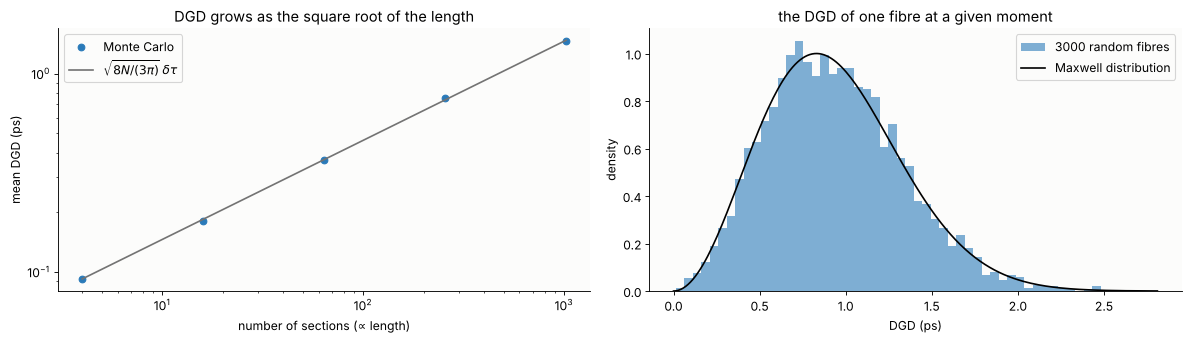

PMD coefficient 0.50 ps/sqrt(km): mean DGD over 400 km 10.0 ps (10 Gb/s bit: 100 ps, 40 Gb/s: 25 ps)
PMD coefficient 0.10 ps/sqrt(km): mean DGD over 400 km 2.0 ps (10 Gb/s bit: 100 ps, 40 Gb/s: 25 ps)
PMD coefficient 0.04 ps/sqrt(km): mean DGD over 400 km 0.8 ps (10 Gb/s bit: 100 ps, 40 Gb/s: 25 ps)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
dgd_section = 0.05     # ps per section
n_sec = [4, 16, 64, 256, 1024]
means = [fibres.pmd_dgd(n, dgd_section, 300, rng=rng).mean() for n in n_sec]
axes[0].loglog(n_sec, means, "o", color=BLUE, label="Monte Carlo")
axes[0].loglog(n_sec, np.sqrt(8*np.array(n_sec)/(3*np.pi))*dgd_section, color=GREY,
               label=r"$\sqrt{8N/(3\pi)}\,\delta\tau$")
axes[0].set_xlabel("number of sections (∝ length)"); axes[0].set_ylabel("mean DGD (ps)"); axes[0].legend()
axes[0].set_title("DGD grows as the square root of the length")
dgd = fibres.pmd_dgd(400, dgd_section, 3000, rng=rng)
m = dgd.mean()
x = np.linspace(0, 3*m, 200)
s2 = np.pi*m**2/8       # Maxwell: mean = 2 sqrt(2/pi) s
axes[1].hist(dgd, 50, density=True, color=BLUE, alpha=0.6, label="3000 random fibres")
axes[1].plot(x, np.sqrt(2/np.pi)*x**2/s2**1.5*np.exp(-x**2/(2*s2)), color="k", label="Maxwell distribution")
axes[1].set_xlabel("DGD (ps)"); axes[1].set_ylabel("density"); axes[1].legend()
axes[1].set_title("the DGD of one fibre at a given moment")
plt.tight_layout()
plt.show()
for coeff in (0.5, 0.1, 0.04):
    print("PMD coefficient {:.2f} ps/sqrt(km): mean DGD over 400 km {:.1f} ps (10 Gb/s bit: 100 ps, 40 Gb/s: 25 ps)".format(
          coeff, coeff*np.sqrt(400)))

A rule of thumb for on-off keying is a mean DGD below 10 to 15 % of the bit
period. Old fibres with 0.5 ps/√km limit 10 Gb/s to some 400 km; modern
fibres (0.04 ps/√km and below, achieved by spinning the preform while
drawing) are no problem at 10 Gb/s and need care only at 40 Gb/s and
beyond, where coherent receivers undo PMD in their signal processing.

## Summary

- **Definitions:** group delay $\tau = LN_g/c$,
  $D = -(\lambda/c)\,d^2n_{eff}/d\lambda^2$ in ps/(nm km),
  $\beta_2 = -D\lambda^2/(2\pi c)$ (−22.5 ps²/km for 17.6 ps/(nm km) at
  1550 nm). D is computed from the mode solver with the material dispersion
  of Fleming's GeO₂–SiO₂ data.
- **Material:** zero at 1270 nm for silica, shifting to longer wavelengths
  with GeO₂; −84 ps/(nm km) at 850 nm, +22 at 1550 nm. Same GVD as
  `ultrafast.gvd()`.
- **Standard fibre:** waveguide dispersion of −2 to −5 ps/(nm km) moves the
  zero to 1301 nm; 17.6 ps/(nm km) at 1550 nm, slope 0.088 ps/(nm² km),
  within G.652. Gloge's $D_{mat} + D_{wg}$ agrees to a few tenths.
- **Profile design:** a triangular core moves the zero to 1550 nm, a W
  profile keeps |D| below about 2.5 ps/(nm km) from 1300 to 1600 nm.
- **Intermodal:** mode-resolved group delays of step and graded fibres lie
  on the WKB curve of the rays (graded: within 2 ps/km below 70 % depth;
  step: within 10 %, the evanescent tails make the high modes faster),
  except near cutoff. Profile dispersion moves
  the optimal α with the wavelength.
- **PMD:** mean DGD ∝ √L, Maxwell distributed; 0.04 to 0.5 ps/√km.

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 26 s


## References

- D. Gloge, "Dispersion in weakly guiding fibers", Appl. Opt. 10,
  2442–2445 (1971).
- J. W. Fleming, "Dispersion in GeO₂–SiO₂ glasses", Appl. Opt. 23,
  4486–4493 (1984).
- R. Olshansky and D. B. Keck, "Pulse broadening in graded-index optical
  fibers", Appl. Opt. 15, 483–491 (1976).
- G. P. Agrawal, *Fiber-Optic Communication Systems*, 4th ed., Wiley
  (2010), chapter 2.
- K. Okamoto, *Fundamentals of Optical Waveguides*, 2nd ed., Academic
  Press (2006), chapter 3 (dispersion-shifted and -flattened profiles).
- J. P. Gordon and H. Kogelnik, "PMD fundamentals: polarization mode
  dispersion in optical fibers", PNAS 97, 4541–4550 (2000).
- ITU-T G.652, G.653 and G.655; Corning SMF-28 Ultra product information.